# BÀI THỰC HÀNH 1 - BÀI 2 (TRANG 30)
## TIỀN XỬ LÝ DỮ LIỆU MÔI TRƯỜNG NHÀ XƯỞNG
- **Học viên:** Nguyễn Minh Vương
- **MSSV:** 6451071090
- **Môn học:** Khai thác dữ liệu

In [1]:
# Cài đặt thư viện nếu chạy trên Google Colab
# !pip install pandas numpy matplotlib seaborn openpyxl gdown

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Tự động tải thư mục dataset từ link Google Drive
if not os.path.exists("dataset") or len(os.listdir("dataset")) == 0:
    try:
        import gdown
        drive_folder_url = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m"
        print("Đang tải dataset từ Google Drive...")
        gdown.download_folder(drive_folder_url, output="dataset", quiet=False, use_cookies=False)
        print("✅ Tải dataset thành công!")
    except Exception as e:
        print("Lưu ý: Nếu chưa có thư viện gdown, hãy chạy lệnh: !pip install gdown")

print("Nguyễn Minh Vương - 6451071090")


Nguyễn Minh Vương - 6451071090


### Câu a: Thêm vào tiêu đề các cột theo thứ tự: id, device_id, co_level, humidity, temperature, time

In [2]:
print("Nguyễn Minh Vương - 6451071090")

df = pd.read_excel('dataset/tb_tracking.xlsx', header=None)

# Đặt tên các cột theo đúng thứ tự yêu cầu
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột\n")

print("--- 5 dòng đầu tiên với tiêu đề cột mới ---")
display(df.head())

print("\n--- Cấu trúc và kiểu dữ liệu (info) ---")
df.info()


Nguyễn Minh Vương - 6451071090
Kích thước tập dữ liệu: 33340 dòng, 6 cột

--- 5 dòng đầu tiên với tiêu đề cột mới ---


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01



--- Cấu trúc và kiểu dữ liệu (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33340 entries, 0 to 33339
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           33339 non-null  float64       
 1   device_id    33339 non-null  float64       
 2   co_level     33339 non-null  float64       
 3   humidity     33339 non-null  float64       
 4   temperature  33339 non-null  float64       
 5   time         33339 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(5)
memory usage: 1.5 MB


### Câu b: Lọc dữ liệu đo được bắt đầu từ ngày 03/01/2018 (loại bỏ dữ liệu trước ngày này)

In [3]:
print("Nguyễn Minh Vương - 6451071090")

# Chuyển cột time sang kiểu datetime
df['time'] = pd.to_datetime(df['time'])

so_dong_goc = len(df)
df_filtered = df[df['time'] >= '2018-01-03'].copy()
so_dong_sau_loc = len(df_filtered)

print(f"Số dòng dữ liệu ban đầu: {so_dong_goc}")
print(f"Số dòng dữ liệu sau khi lọc (từ 03/01/2018): {so_dong_sau_loc}")
print(f"Số dòng dữ liệu không chính xác bị loại bỏ: {so_dong_goc - so_dong_sau_loc}\n")

print("Thời điểm đo nhỏ nhất sau khi lọc:", df_filtered['time'].min())
print("Thời điểm đo lớn nhất sau khi lọc:", df_filtered['time'].max())

display(df_filtered.head())


Nguyễn Minh Vương - 6451071090
Số dòng dữ liệu ban đầu: 33340
Số dòng dữ liệu sau khi lọc (từ 03/01/2018): 1918
Số dòng dữ liệu không chính xác bị loại bỏ: 31422

Thời điểm đo nhỏ nhất sau khi lọc: 2018-01-03 13:11:07
Thời điểm đo lớn nhất sau khi lọc: 2018-01-17 15:46:34


,id,device_id,co_level,humidity,temperature,time
31419,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
31420,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
31421,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
31422,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
31423,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


### Câu c: Từ cột time bóc tách dữ liệu thành thời điểm đo đạc trong ngày tính theo phút, đặt tên là minutes

In [4]:
print("Nguyễn Minh Vương - 6451071090")

# Bóc tách thành số phút trong ngày: giờ * 60 + phút + giây / 60
df_filtered['minutes'] = df_filtered['time'].dt.hour * 60 + df_filtered['time'].dt.minute + df_filtered['time'].dt.second / 60.0

print("Hiển thị 5 dòng đầu tiên với cột 'minutes' mới tạo:")
display(df_filtered[['time', 'minutes', 'co_level', 'humidity', 'temperature']].head())

print("\nThống kê mô tả cột 'minutes':")
print(df_filtered['minutes'].describe())


Nguyễn Minh Vương - 6451071090
Hiển thị 5 dòng đầu tiên với cột 'minutes' mới tạo:


,time,minutes,co_level,humidity,temperature
31419,2018-01-03 13:11:07,791.116667,2.0,3.0,4.0
31420,2018-01-03 13:15:10,795.166667,2.0,3.0,4.0
31421,2018-01-03 13:17:30,797.500000,58.0,26.0,0.0
31422,2018-01-03 13:19:21,799.350000,58.0,26.0,0.0
31423,2018-01-03 13:24:17,804.283333,58.0,26.0,0.0



Thống kê mô tả cột 'minutes':
count    1918.000000
mean      709.917240
std       391.870574
min         1.500000
25%       396.275000
50%       713.716667
75%       992.716667
max      1439.000000
Name: minutes, dtype: float64


### Câu d: Vẽ đồ thị phân tán (scatter-plots) lần lượt biểu diễn dữ liệu nồng độ khí CO, độ ẩm và nhiệt độ theo cột minutes

Nguyễn Minh Vương - 6451071090


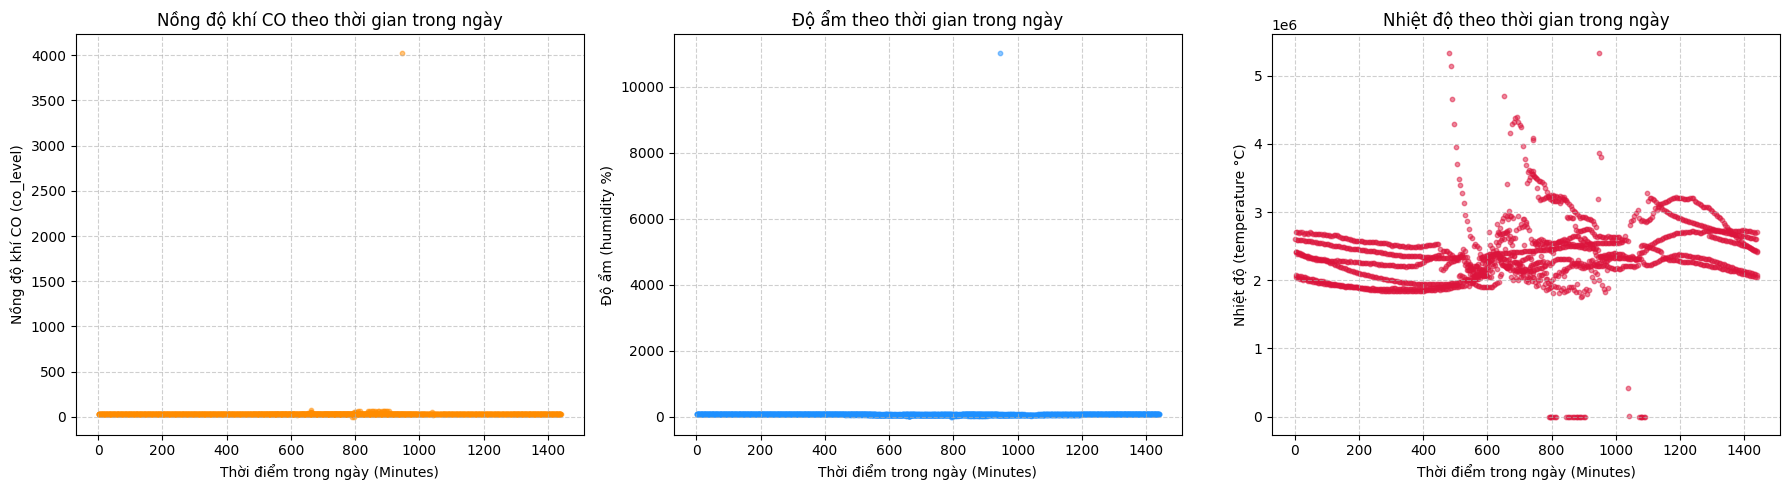

In [5]:
print("Nguyễn Minh Vương - 6451071090")

plt.figure(figsize=(18, 5))

# 1. Đồ thị phân tán: minutes vs co_level
plt.subplot(1, 3, 1)
plt.scatter(df_filtered['minutes'], df_filtered['co_level'], alpha=0.5, color='darkorange', s=10)
plt.title('Nồng độ khí CO theo thời gian trong ngày', fontsize=12)
plt.xlabel('Thời điểm trong ngày (Minutes)', fontsize=10)
plt.ylabel('Nồng độ khí CO (co_level)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Đồ thị phân tán: minutes vs humidity
plt.subplot(1, 3, 2)
plt.scatter(df_filtered['minutes'], df_filtered['humidity'], alpha=0.5, color='dodgerblue', s=10)
plt.title('Độ ẩm theo thời gian trong ngày', fontsize=12)
plt.xlabel('Thời điểm trong ngày (Minutes)', fontsize=10)
plt.ylabel('Độ ẩm (humidity %)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

# 3. Đồ thị phân tán: minutes vs temperature
plt.subplot(1, 3, 3)
plt.scatter(df_filtered['minutes'], df_filtered['temperature'], alpha=0.5, color='crimson', s=10)
plt.title('Nhiệt độ theo thời gian trong ngày', fontsize=12)
plt.xlabel('Thời điểm trong ngày (Minutes)', fontsize=10)
plt.ylabel('Nhiệt độ (temperature °C)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
